# Subtopic 2 - Effect of Collaboration on Musical Attributes

<b>How do the musical attributes change when artists collaborate compared to when they work solo?</b>


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)


In [3]:
df=pd.read_csv('dataset.csv')
df.info()
# we want to check for the data and its type to see if there is any missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

# DATA CLEANING

In [5]:
# dropping index column, its redundant
df.drop(columns=['Unnamed: 0'], inplace=True)

#we delete the row that contain no value
missing_data_rows = df[df.isnull().any(axis=1)]
print(missing_data_rows)

df_filtered = df.drop(index=65900)


                     track_id artists album_name track_name  popularity  \
65900  1kR4gIb7nGxHPI3D2ifs59     NaN        NaN        NaN           0   

       duration_ms  explicit  danceability  energy  key  loudness  mode  \
65900            0     False         0.501   0.583    7     -9.46     0   

       speechiness  acousticness  instrumentalness  liveness  valence  \
65900       0.0605          0.69           0.00396    0.0747    0.734   

         tempo  time_signature track_genre  
65900  138.391               4       k-pop  


In [6]:
# we check to see if we have any duplicated row and delete it if we have
duplicated_rows = df_filtered[df_filtered.duplicated()]

# there are 450 duplicated rows and we want to drop those rows
print(duplicated_rows.shape)
df_filtered = df_filtered.drop_duplicates()


(450, 20)


In [7]:
# change to lowercase
df_filtered[['artists', 'album_name', 'track_name', 'track_genre']] = df_filtered[['artists', 'album_name', 'track_name', 'track_genre']].applymap(str.lower)

# strip whitespace
df_filtered[['artists', 'album_name', 'track_name', 'track_genre']] = df_filtered[['artists', 'album_name', 'track_name', 'track_genre']].applymap(str.strip)

df_filtered.shape

(113549, 20)

In [8]:
# we realized that there are many rows that have the same track_id but different genres
# we want to create new columns to list all the genres in the same track and drop all the duplicate rows
df_filtered['all_genres'] = df_filtered.groupby('track_id')['track_genre'].transform(lambda x: '; '.join(set(x)))
df_filtered['all_genres']=df_filtered['all_genres'].str.split(';')

# Drop duplicate rows based on track_id
df_filtered = df_filtered.drop_duplicates(subset='track_id').reset_index(drop=True)

df_filtered.shape

(89740, 21)

In [9]:
# Convert duration from milliseconds to minutes to make it easier to understand
df_filtered['duration_min'] = df_filtered['duration_ms'] / 60000

#  check the range of each variable to see if there is any outliers
# df_filtered['duration_min'].describe()

# although there are some tracks have a very long duration, we do not know if it have any bad effects at this moment
# we will still check multiple cases to see if our team should drop those tracks later



In [10]:
# remove exclusive speech recording (e.g. talk show, audio book, poetry)
# Values above 0.66 describe tracks that are probably made entirely of spoken words
df_filtered = df_filtered[df_filtered['speechiness'] < 0.66]
df_filtered.shape

(88871, 22)

In [11]:
# Create a new column 'artist_count' that counts the number of artists and then use it to check whether it it 'solo' or 'collaboration'
df_filtered['artist_count'] = df_filtered['artists'].str.split(';').apply(len)

df_filtered['collaboration'] = df_filtered['artist_count'].apply(lambda x: 'collaboration' if x > 1 else 'solo')

# new column: split the artists
df_filtered['artists_split'] = df_filtered['artists'].str.split(';')

# Explode the dataset so each artist gets its own row
df_exploded = df_filtered.explode('artists_split').rename(columns={'artists_split': 'individual_artist'})

#  Determine if each artist has both solo and collaboration tracks (if they have both solo and collaboration songs, the unique number will be 2)
artist_status = df_exploded.groupby('individual_artist')['collaboration'].nunique()
artist_status_dict = artist_status.apply(lambda x: 'yes' if x > 1 else 'no').to_dict()


df_filtered['status'] = df_filtered['artists_split'].apply(
    lambda artists: 'both' if any(artist_status_dict.get(artist.strip(), 'no') == 'yes' for artist in artists) else 'one')

# Since we want to analyze how the musical attributes of tracks change when artists collaborate compared to when they work solo, we want to keep 
# all rows where the status is 'both', as it indicates artists who have both solo and collaboration songs, allowing us to compare the differences

df_filtered = df_filtered[df_filtered['status'] == 'both'].reset_index(drop=True)

df_filtered



,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,all_genres,duration_min,artist_count,collaboration,artists_split,status
0,1iJBSr7s7jYXzM8EGcbK5b,ingrid michaelson;zayn,to begin again,to begin again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic,[acoustic],3.513767,2,collaboration,"[ingrid michaelson, zayn]",both
1,6lfxq3CG4xtTiEg7opyCyx,kina grannis,crazy rich asians (original motion picture sou...,can't help falling in love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic,[acoustic],3.365550,1,solo,[kina grannis],both
2,5vjLSffimiIP26QG5WcN2K,chord overstreet,hold on,hold on,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic,[acoustic],3.314217,1,solo,[chord overstreet],both
3,6Vc5wAMmXdKIAM7WUoEb7N,a great big world;christina aguilera,is there anybody out there?,say something,74,229400,False,0.407,0.1470,2,-8.822,1,0.0355,0.8570,0.000003,0.0913,0.0765,141.284,3,acoustic,"[piano, acoustic]",3.823333,2,collaboration,"[a great big world, christina aguilera]",both
4,1EzrEOXmMH3G43AXT1y7pA,jason mraz,we sing. we dance. we steal things.,i'm yours,80,242946,False,0.703,0.4440,11,-9.331,1,0.0417,0.5590,0.000000,0.0973,0.7120,150.960,4,acoustic,"[rock, acoustic]",4.049100,1,solo,[jason mraz],both
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51261,4OkMK49i3NApR1KsAIsTf6,chris tomlin,see the morning (special edition),how can i keep from singing,39,256026,False,0.505,0.6870,10,-4.375,1,0.0287,0.0841,0.000000,0.1880,0.3820,104.083,3,world-music,[world-music],4.267100,1,solo,[chris tomlin],both
51262,4WbOUe6T0sozC7z5ZJgiAA,lucas cervetti,frecuencias álmicas en 432hz,"frecuencia álmica, pt. 4",22,305454,False,0.331,0.1710,1,-15.668,1,0.0350,0.9200,0.022900,0.0679,0.3270,132.147,3,world-music,[world-music],5.090900,1,solo,[lucas cervetti],both
51263,6x8ZfSoqDjuNa5SVP5QjvX,cesária evora,best of,miss perfumado,22,271466,False,0.629,0.3290,0,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music,[world-music],4.524433,1,solo,[cesária evora],both
51264,2e6sXL2bYv4bSz6VTdnfLs,michael w. smith,change your world,friends,41,283893,False,0.587,0.5060,7,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music,[world-music],4.731550,1,solo,[michael w. smith],both


In [12]:
# the number of genres in this dataset after all the data cleaning steps
print(len(df_filtered['track_genre'].unique()))
df_filtered['track_genre'].unique()

113


array(['acoustic', 'afrobeat', 'alt-rock', 'alternative', 'ambient',
       'anime', 'black-metal', 'bluegrass', 'blues', 'brazil',
       'breakbeat', 'british', 'cantopop', 'chicago-house', 'children',
       'chill', 'classical', 'club', 'comedy', 'country', 'dance',
       'dancehall', 'death-metal', 'deep-house', 'detroit-techno',
       'disco', 'disney', 'drum-and-bass', 'dub', 'dubstep', 'edm',
       'electro', 'electronic', 'emo', 'folk', 'forro', 'french', 'funk',
       'garage', 'german', 'gospel', 'goth', 'grindcore', 'groove',
       'grunge', 'guitar', 'happy', 'hard-rock', 'hardcore', 'hardstyle',
       'heavy-metal', 'hip-hop', 'honky-tonk', 'house', 'idm', 'indian',
       'indie-pop', 'indie', 'industrial', 'iranian', 'j-dance', 'j-idol',
       'j-pop', 'j-rock', 'jazz', 'k-pop', 'kids', 'latin', 'latino',
       'malay', 'mandopop', 'metal', 'metalcore', 'minimal-techno', 'mpb',
       'new-age', 'opera', 'pagode', 'party', 'piano', 'pop-film', 'pop',
       'pow

# Hypothesis Testing for Comparing Solo vs. Collaboration Tracks
Hypothesis testing is a statistical method used to determine whether there is enough evidence to reject a null hypothesis in favor of an alternative hypothesis. By setting up a null hypothesis (no difference between solo and collaboration songs) and an alternative hypothesis (there exist difference between solo and collaboration songs), we can makes data-driven decisions while quantifying uncertainty, ensuring that any differences found are not just due to random variation.

### Steps for Hypothesis Testing
**State the Hypothesis**:
   - Null Hypothesis (H₀): There is no difference between the musical attrergy) of solo and collaboration tracks
   - Alternative Hypothesis (H₁): There is a significant difference between the musical attribute of solo and collaboration tracks

**Set Significance Level (α = 0.05)**
- If the p-value < α (0.05), reject the null hypothesis. If the p-value ≥ α, fail to reject the null hypothesissting on additional attributes!

# Hypothesis teting for all genres in the dataset

Description: First, a t-test is performed for attributes such as danceability, energy, and others, comparing solo and collaboration tracks for each genre to determine whether the differences are statistically significant. Based on the results, each attribute is labeled as "increase," "decrease," or "no change," depending on the direction of the difference or its insignificance. Next, the code counts the occurrences of these labels across all genres, summarizing the overall trends for each attribute.This provides a detailed understanding of how collaborations influence musical attributes and highlights the specific genres where these changes are most pronounced or entirely absent.

In [15]:
# Explode the 'all_genres' column so that each genre becomes its own row
df_filtered = df_filtered.explode('all_genres')
df_filtered['all_genres'] = df_filtered['all_genres'].str.strip()

import scipy.stats as stats
attributes = ['danceability', 'energy', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
results_list = []

# for each genre
for genre in df_filtered['all_genres'].unique():
    genre_data = df_filtered[df_filtered['all_genres'] == genre]
    
    # create a dictionary to hold the results for each genre
    genre_result = {'track_genre': genre}
    
    # each attribute
    for attribute in attributes:
        solo_data = genre_data[genre_data['collaboration'] == 'solo'][attribute]
        collab_data = genre_data[genre_data['collaboration'] == 'collaboration'][attribute]
        
        #t-test
        t_stat, p_value = stats.ttest_ind(solo_data, collab_data)

        # testing
        if p_value < 0.05:
            mean_solo = solo_data.mean()
            mean_collab = collab_data.mean()

            # Determine the direction of the change: increase or decrease
            if mean_collab > mean_solo:
                genre_result[attribute] = 'increase'
            else:
                genre_result[attribute] = 'decrease'
        else:
            genre_result[attribute] = 'no'

    # Append the results  to the list
    results_list.append(genre_result)

 
results_df = pd.DataFrame(results_list)

results_df


,track_genre,danceability,energy,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,acoustic,no,no,no,no,no,no,no,increase
1,piano,increase,no,increase,no,no,no,no,no
2,rock,increase,decrease,increase,increase,no,no,decrease,decrease
3,chill,no,no,increase,no,no,no,no,no
4,guitar,increase,no,no,no,no,no,decrease,no
...,...,...,...,...,...,...,...,...,...
109,kids,increase,decrease,increase,increase,no,no,decrease,no
110,romance,no,no,no,no,no,no,no,no
111,sleep,decrease,decrease,decrease,no,no,no,no,decrease
112,study,no,decrease,no,no,no,no,no,no


In [16]:
# Count the number of 'increase', 'decrease', and 'no'  
increase_count = (results_df.iloc[:, 1:] == 'increase').sum(axis=0)
decrease_count = (results_df.iloc[:, 1:] == 'decrease').sum(axis=0)
no_change_count = (results_df.iloc[:, 1:] == 'no').sum(axis=0)


print("Number of increases per attribute:")
print(increase_count)
print("\nNumber of decreases per attribute:")
print(decrease_count)
print("\nNumber of no changes per attribute:")
print(no_change_count)

 
# Display the rows showed all changes (either increase or decrease)
all_change_rows = results_df[results_df.iloc[:, 1:].apply(lambda x: all(x != 'no'), axis=1)]
print("\nRows where all attributes showed a change (either increase or decrease):")
print(all_change_rows)

# Display the rows showed no change
no_change_rows = results_df[results_df.iloc[:, 1:].apply(lambda x: all(x == 'no'), axis=1)]
print("\nRows where all attributes showed no change:")
no_change_rows.reset_index()


Number of increases per attribute:
danceability        39
energy              32
speechiness         40
acousticness        15
instrumentalness     9
liveness            16
valence             21
tempo               11
dtype: int64

Number of decreases per attribute:
danceability        12
energy              18
speechiness         14
acousticness        26
instrumentalness    29
liveness            14
valence             27
tempo               15
dtype: int64

Number of no changes per attribute:
danceability        63
energy              64
speechiness         60
acousticness        73
instrumentalness    76
liveness            84
valence             66
tempo               88
dtype: int64

Rows where all attributes showed a change (either increase or decrease):
Empty DataFrame
Columns: [track_genre, danceability, energy, speechiness, acousticness, instrumentalness, liveness, valence, tempo]
Index: []

Rows where all attributes showed no change:


,index,track_genre,danceability,energy,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,15,samba,no,no,no,no,no,no,no,no
1,40,metalcore,no,no,no,no,no,no,no,no
2,66,j-idol,no,no,no,no,no,no,no,no
3,81,mandopop,no,no,no,no,no,no,no,no
4,103,grindcore,no,no,no,no,no,no,no,no
5,105,heavy-metal,no,no,no,no,no,no,no,no
6,107,iranian,no,no,no,no,no,no,no,no
7,110,romance,no,no,no,no,no,no,no,no


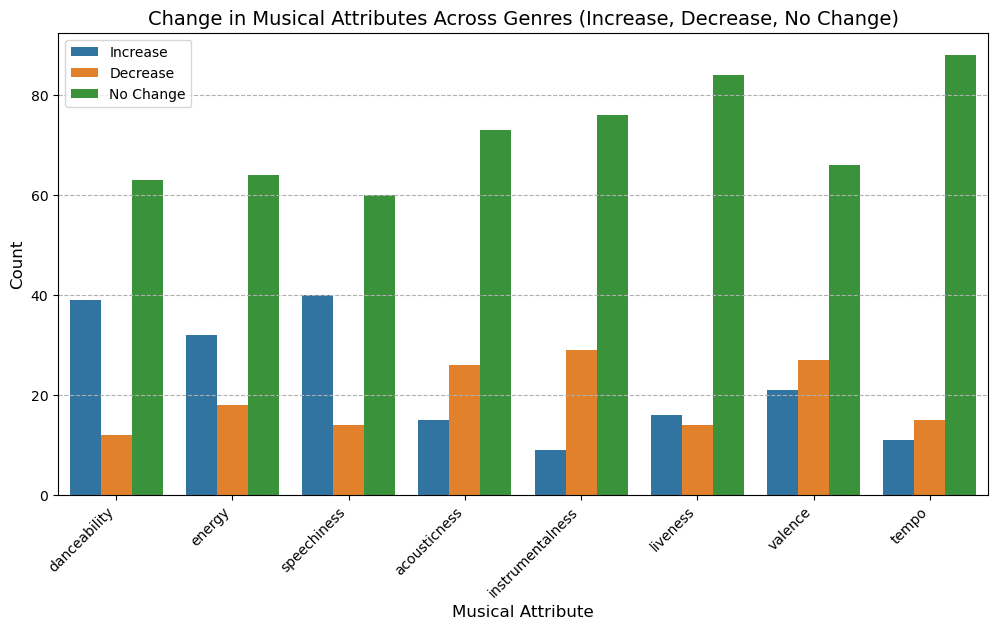

In [17]:
# DataFrame for the counts
change_counts_df = pd.DataFrame({
    'Attribute': increase_count.index,
    'Increase': increase_count.values,
    'Decrease': decrease_count.values,
    'No Change': no_change_count.values})

# Reshape the data for plotting
change_counts_df=change_counts_df.melt(id_vars='Attribute',\
                                       value_vars=['Increase','Decrease','No Change'],var_name='Change Type',value_name='Count')

 
plt.figure(figsize=(12, 6))
sns.barplot(data=change_counts_df, x='Attribute', y='Count', hue='Change Type')

 
plt.title('Change in Musical Attributes Across Genres (Increase, Decrease, No Change)', fontsize=14)
plt.xlabel('Musical Attribute', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.legend( fontsize=10)
plt.grid(axis='y', linestyle='--')

 
plt.show()


## Conclusion: 


### Number of Changes:

Danceability, energy, and speechiness had the highest number of increases (39, 32, and 40, respectively), suggesting that collaboration may often lead to more rhythmic, energetic, and engaging tracks compared to solo tracks in these attributes.  
Acousticness, instrumentalness, liveness, valence, and tempo showed relatively fewer increases, which may suggest that collaboration has less of an impact on these specific attributes.  
On the other hand, the decreases were most significant for attributes like instrumentalness, acousticness, and valence, all of which had 26 or more decreases. This may indicate that in some genres, collaboration may result in a reduction in instrumental complexity or a shift in the emotional tone compared to solo tracks.

### No Change:

The majority of attributes had a large number of no changes, particularly instrumentalness (76), liveness (84), and tempo (88), indicating that for many genres, collaboration does not significantly alter these aspects of a track.  
Speechiness, energy, and danceability showed fewer instances of no change, which suggests that these attributes are more likely to be impacted by collaboration, either increasing or decreasing, compared to others.

### Rows with All Changes:

There were 0 genres where all attributes showed a significant change (either increase or decrease), suggesting that collaboration impacts different musical attributes differently within the same genre.

### Rows with No Change:

8 genres had no change across all attributes. These genres show that for certain genres, collaboration may not have a significant effect on the musical characteristics of the tracks. This stability could suggest that the inherent style or structure of these genres remains consistent, regardless of whether the track is a solo or collaboration.

### Overall Summary:  
The effects of collaboration on musical attributes are genre-dependent. While collaboration appears to enhance certain aspects (like danceability and energy) in some genres, it may decrease others (such as instrumentalness or tempo) in different genres. However, many genres showed no significant changes across most musical attributes, indicating that collaboration does not always alter the essential characteristics of tracks in those genres.

# More Detailed: Compare All The Music Attribute Across Top 10 Genres based on 'Popularity' (Solo vs Collaboration)

In this part, we want to focus on the most 10 popular song to make it more narrow so that the data is more insightful. We can also narrow it to smaller dataset based on different purposes.

Calculating hypothesis testing for each music attribute across the most popular genres is important to identify patterns in how solo and collaborative tracks differ in their musical characteristics. By analyzing these patterns, we can gain insights into the attributes that resonate most with listeners and understand whether collaborations bring unique qualities to popular music genres. 

In [20]:
df_exploded_genres = df_filtered

# Group by genres and calculate the mean
genre_popularity = df_exploded_genres.groupby('all_genres')['popularity'].mean()

# Sort by popularity  
top_genres = genre_popularity.sort_values(ascending=False).head(10)
 

# Filter the dataset  with the top 10 genres
df_top = df_exploded_genres[df_exploded_genres['all_genres'].isin(top_genres.index)]

# Get the list of the top genres
top_genres= list(top_genres.index)
top_genres

['pop-film',
 'k-pop',
 'grunge',
 'sad',
 'chill',
 'emo',
 'anime',
 'indian',
 'metalcore',
 'sertanejo']

## Create a function to calculate the hypothesis testing for each music attribute accross the top 10 most popular genres


In [22]:
from scipy import stats
def testing(name):
    for genre in top_genres:
        genre_data = df_top[df_top['all_genres'] == genre]
        
        # Separate the solo and collaboration data
        solo_data = genre_data[genre_data['collaboration'] == 'solo'][name]
        collab_data = genre_data[genre_data['collaboration'] == 'collaboration'][name]
    
        t_stat, p_value = stats.ttest_ind(solo_data, collab_data)
    
        print(f"Genre: {genre}")
        print(f"T-statistic: {t_stat:.5f}, P-value: {p_value:.5f}")
        
        if p_value < 0.05:
            print(f"Significant difference in {name} between solo and collaboration tracks for {genre}")
    
            mean_solo = solo_data.mean()
            mean_collab = collab_data.mean()
    
            # Determine how the musical attribute changes in direction
            if mean_collab > mean_solo:
                print(f"(Collaboration mean: {mean_collab:.3f}, Solo mean: {mean_solo:.3f})")
                print(f"-> {name} increase with collaboration. \n")
                
            else:
                print(f"(Collaboration mean: {mean_collab:.3f}, Solo mean: {mean_solo:.3f})")
                print(f"-> {name} decreases with collaboration. \n")
                
        else:
            print(f"No significant difference in {name} between solo and collaboration tracks for {genre}\n")


### 1. Danceability

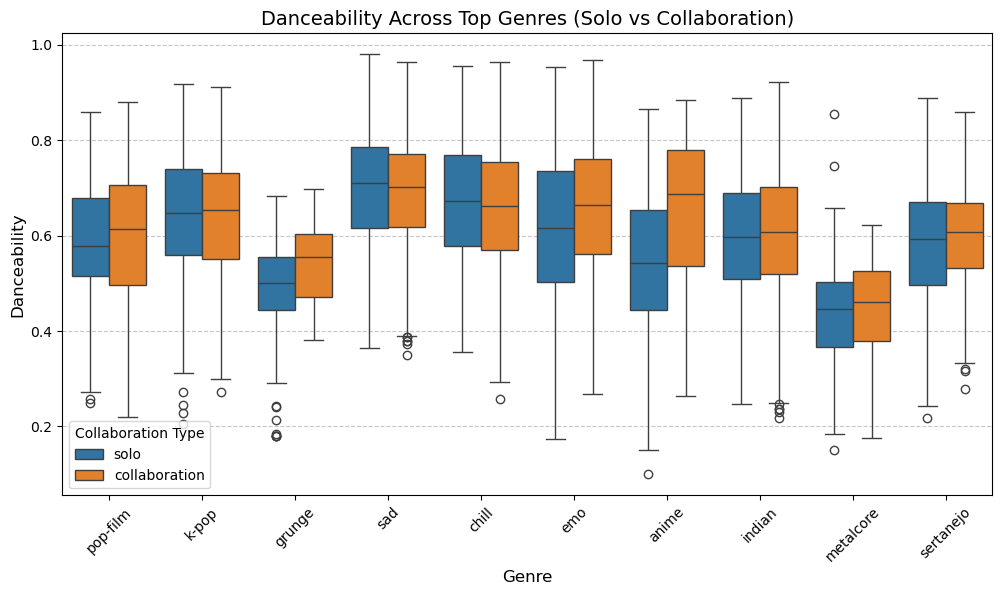

Genre: pop-film
T-statistic: -1.41496, P-value: 0.15742
No significant difference in danceability between solo and collaboration tracks for pop-film

Genre: k-pop
T-statistic: 0.79343, P-value: 0.42776
No significant difference in danceability between solo and collaboration tracks for k-pop

Genre: grunge
T-statistic: -2.53317, P-value: 0.01181
Significant difference in danceability between solo and collaboration tracks for grunge
(Collaboration mean: 0.541, Solo mean: 0.493)
-> danceability increase with collaboration. 

Genre: sad
T-statistic: 1.21855, P-value: 0.22342
No significant difference in danceability between solo and collaboration tracks for sad

Genre: chill
T-statistic: 0.76079, P-value: 0.44708
No significant difference in danceability between solo and collaboration tracks for chill

Genre: emo
T-statistic: -2.94048, P-value: 0.00339
Significant difference in danceability between solo and collaboration tracks for emo
(Collaboration mean: 0.654, Solo mean: 0.615)
-> dance

In [24]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='all_genres', y='danceability', hue='collaboration',order=top_genres)
plt.title('Danceability Across Top Genres (Solo vs Collaboration)', fontsize=14)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Danceability', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.legend(title='Collaboration Type', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

testing('danceability')

### 2. Liveness

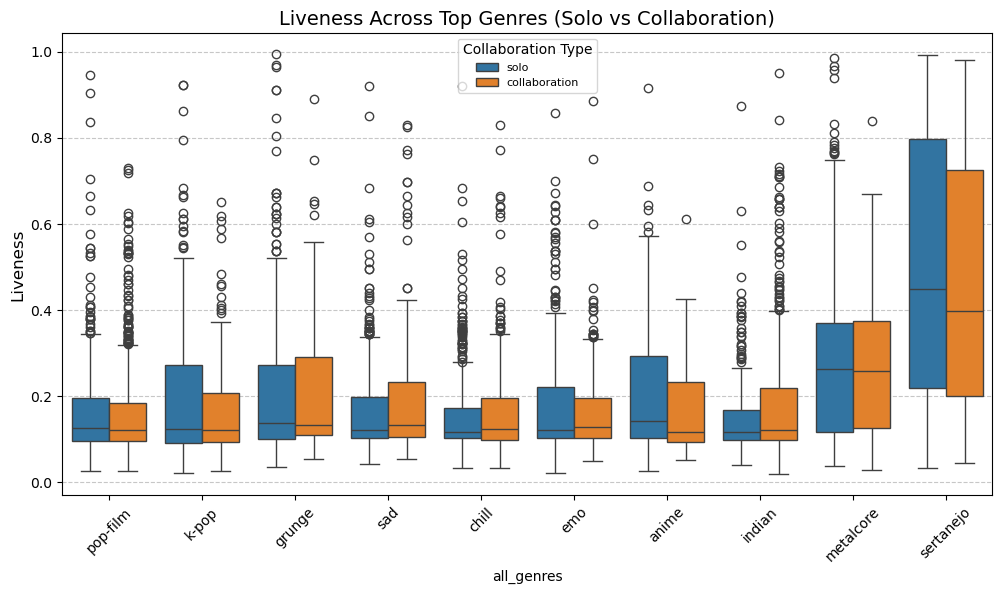

Genre: pop-film
T-statistic: 1.14924, P-value: 0.25076
No significant difference in liveness between solo and collaboration tracks for pop-film

Genre: k-pop
T-statistic: 2.77088, P-value: 0.00572
Significant difference in liveness between solo and collaboration tracks for k-pop
(Collaboration mean: 0.163, Solo mean: 0.188)
-> liveness decreases with collaboration. 

Genre: grunge
T-statistic: -0.77826, P-value: 0.43703
No significant difference in liveness between solo and collaboration tracks for grunge

Genre: sad
T-statistic: -1.92054, P-value: 0.05519
No significant difference in liveness between solo and collaboration tracks for sad

Genre: chill
T-statistic: -1.42431, P-value: 0.15488
No significant difference in liveness between solo and collaboration tracks for chill

Genre: emo
T-statistic: 0.75847, P-value: 0.44843
No significant difference in liveness between solo and collaboration tracks for emo

Genre: anime
T-statistic: 2.20892, P-value: 0.02781
Significant difference in

In [26]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='all_genres', y='liveness', hue='collaboration',order=top_genres)
plt.title('Liveness Across Top Genres (Solo vs Collaboration)', fontsize=14)
plt.ylabel('Liveness', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.legend(title='Collaboration Type', fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

testing('liveness')

### 3. Instrumentalness

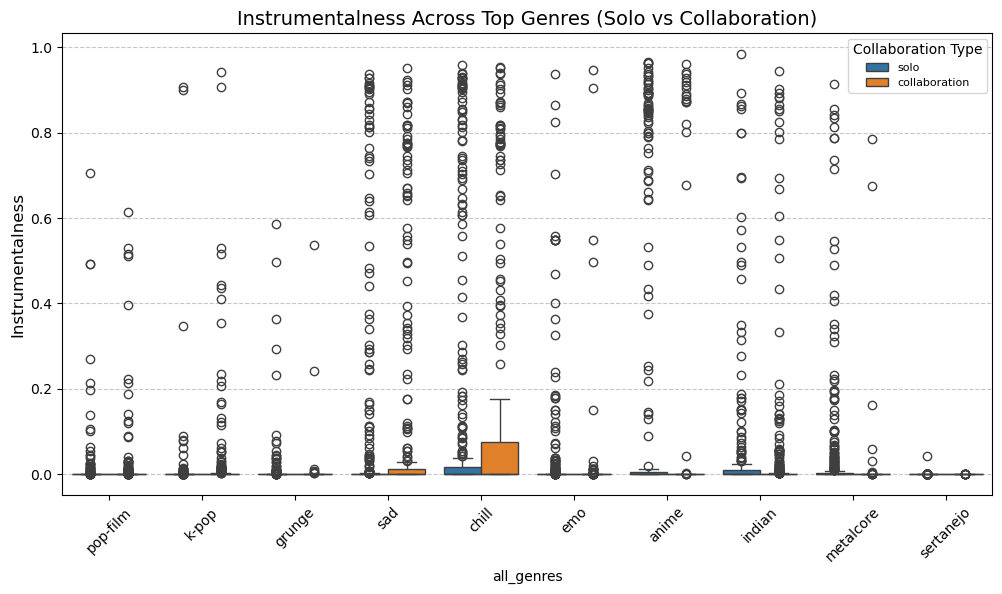

Genre: pop-film
T-statistic: 0.82012, P-value: 0.41236
No significant difference in instrumentalness between solo and collaboration tracks for pop-film

Genre: k-pop
T-statistic: -2.19304, P-value: 0.02858
Significant difference in instrumentalness between solo and collaboration tracks for k-pop
(Collaboration mean: 0.018, Solo mean: 0.006)
-> instrumentalness increase with collaboration. 

Genre: grunge
T-statistic: -1.35519, P-value: 0.17638
No significant difference in instrumentalness between solo and collaboration tracks for grunge

Genre: sad
T-statistic: -1.51800, P-value: 0.12946
No significant difference in instrumentalness between solo and collaboration tracks for sad

Genre: chill
T-statistic: -1.40853, P-value: 0.15949
No significant difference in instrumentalness between solo and collaboration tracks for chill

Genre: emo
T-statistic: 0.65188, P-value: 0.51470
No significant difference in instrumentalness between solo and collaboration tracks for emo

Genre: anime
T-statis

In [28]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='all_genres', y='instrumentalness', hue='collaboration',order=top_genres)
plt.title('Instrumentalness Across Top Genres (Solo vs Collaboration)', fontsize=14)
plt.ylabel('Instrumentalness', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.legend(title='Collaboration Type', fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

testing('instrumentalness')


### 4. Energy

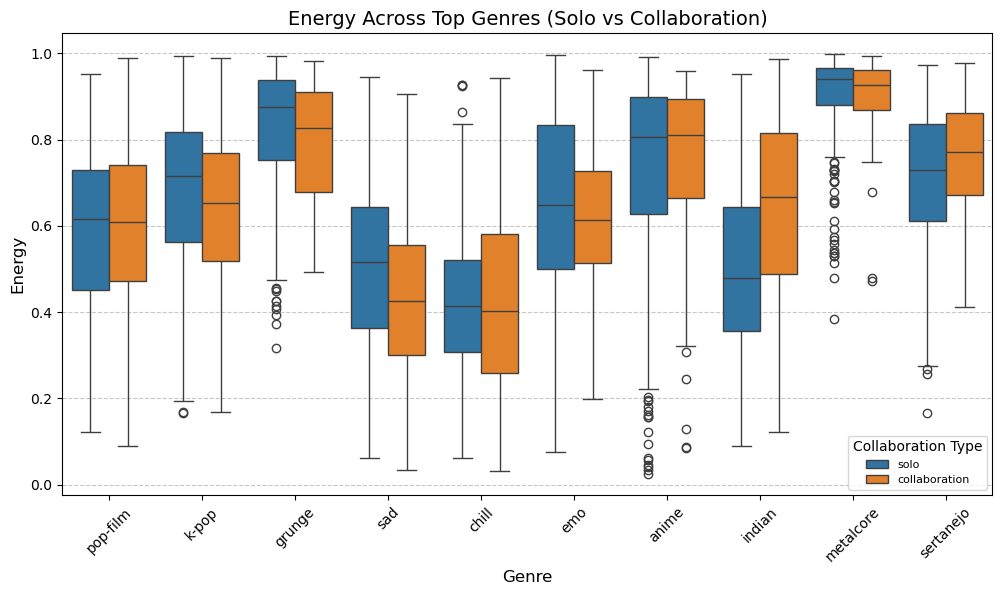

Genre: pop-film
T-statistic: -1.24458, P-value: 0.21361
No significant difference in energy between solo and collaboration tracks for pop-film

Genre: k-pop
T-statistic: 3.65313, P-value: 0.00028
Significant difference in energy between solo and collaboration tracks for k-pop
(Collaboration mean: 0.638, Solo mean: 0.683)
-> energy decreases with collaboration. 

Genre: grunge
T-statistic: 1.19595, P-value: 0.23266
No significant difference in energy between solo and collaboration tracks for grunge

Genre: sad
T-statistic: 5.73505, P-value: 0.00000
Significant difference in energy between solo and collaboration tracks for sad
(Collaboration mean: 0.430, Solo mean: 0.509)
-> energy decreases with collaboration. 

Genre: chill
T-statistic: 0.07910, P-value: 0.93698
No significant difference in energy between solo and collaboration tracks for chill

Genre: emo
T-statistic: 1.59997, P-value: 0.11006
No significant difference in energy between solo and collaboration tracks for emo

Genre: an

In [30]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='all_genres', y='energy', hue='collaboration',order=top_genres)
plt.title('Energy Across Top Genres (Solo vs Collaboration)', fontsize=14)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Energy', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.legend(title='Collaboration Type', fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

testing('energy')

### 5. Acousticness

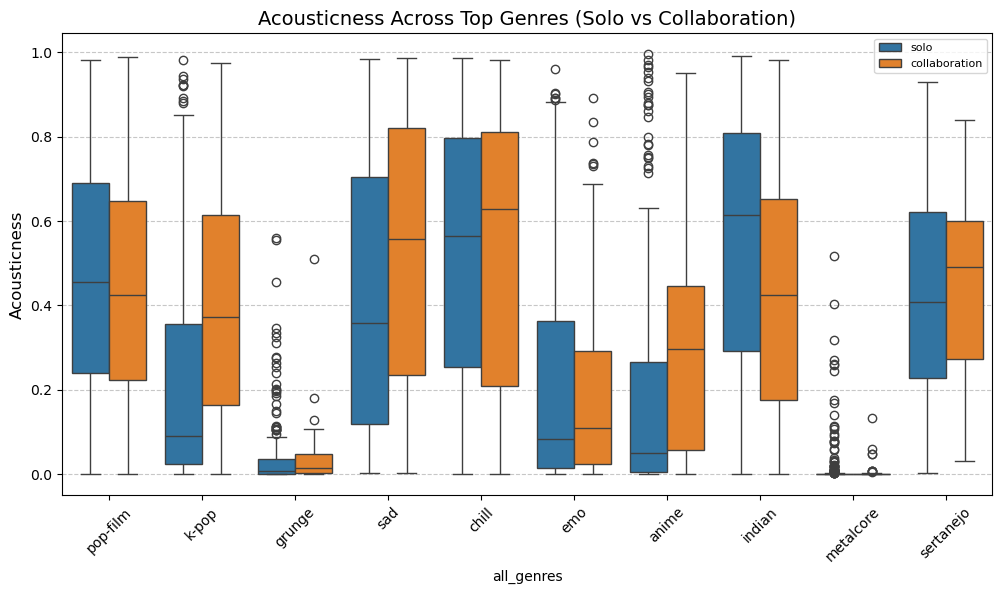

Genre: pop-film
T-statistic: 1.40814, P-value: 0.15943
No significant difference in acousticness between solo and collaboration tracks for pop-film

Genre: k-pop
T-statistic: -9.48472, P-value: 0.00000
Significant difference in acousticness between solo and collaboration tracks for k-pop
(Collaboration mean: 0.402, Solo mean: 0.223)
-> acousticness increase with collaboration. 

Genre: grunge
T-statistic: -0.69945, P-value: 0.48481
No significant difference in acousticness between solo and collaboration tracks for grunge

Genre: sad
T-statistic: -4.70408, P-value: 0.00000
Significant difference in acousticness between solo and collaboration tracks for sad
(Collaboration mean: 0.526, Solo mean: 0.415)
-> acousticness increase with collaboration. 

Genre: chill
T-statistic: -0.45308, P-value: 0.65066
No significant difference in acousticness between solo and collaboration tracks for chill

Genre: emo
T-statistic: 1.13383, P-value: 0.25726
No significant difference in acousticness between

In [32]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='all_genres', y='acousticness', hue='collaboration',order=top_genres)
plt.title('Acousticness Across Top Genres (Solo vs Collaboration)', fontsize=14)
plt.ylabel('Acousticness', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.legend( fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

testing('acousticness')

### 6. Speechiness

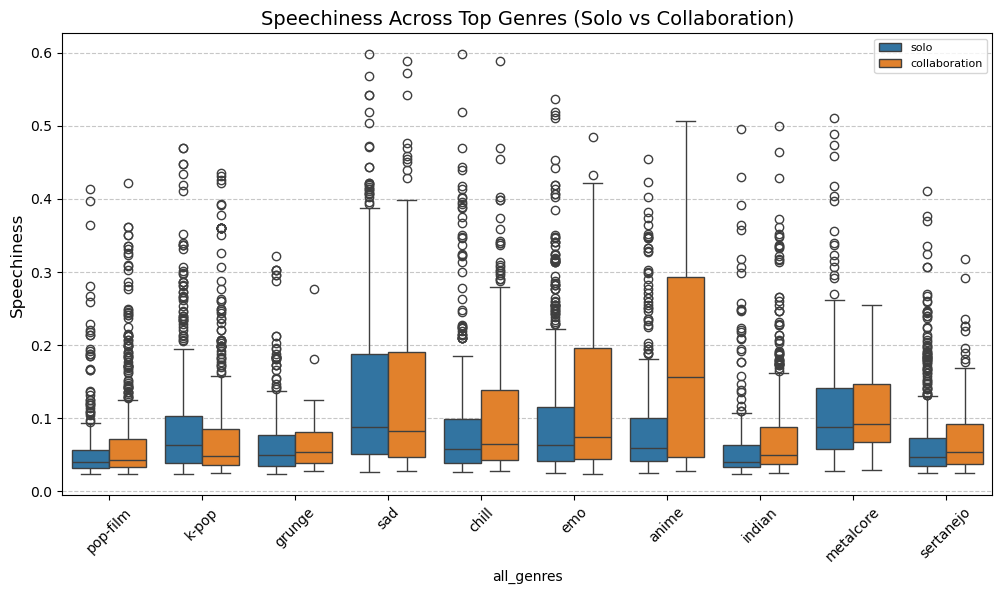

Genre: pop-film
T-statistic: -2.18324, P-value: 0.02927
Significant difference in speechiness between solo and collaboration tracks for pop-film
(Collaboration mean: 0.067, Solo mean: 0.058)
-> speechiness increase with collaboration. 

Genre: k-pop
T-statistic: 1.08024, P-value: 0.28035
No significant difference in speechiness between solo and collaboration tracks for k-pop

Genre: grunge
T-statistic: 0.01523, P-value: 0.98786
No significant difference in speechiness between solo and collaboration tracks for grunge

Genre: sad
T-statistic: 0.42301, P-value: 0.67242
No significant difference in speechiness between solo and collaboration tracks for sad

Genre: chill
T-statistic: -1.96950, P-value: 0.04936
Significant difference in speechiness between solo and collaboration tracks for chill
(Collaboration mean: 0.111, Solo mean: 0.095)
-> speechiness increase with collaboration. 

Genre: emo
T-statistic: -3.11913, P-value: 0.00189
Significant difference in speechiness between solo and co

In [34]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='all_genres', y='speechiness', hue='collaboration',order=top_genres)
plt.title('Speechiness Across Top Genres (Solo vs Collaboration)', fontsize=14)
plt.ylabel('Speechiness', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.legend( fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

testing('speechiness')

### 7. Tempo

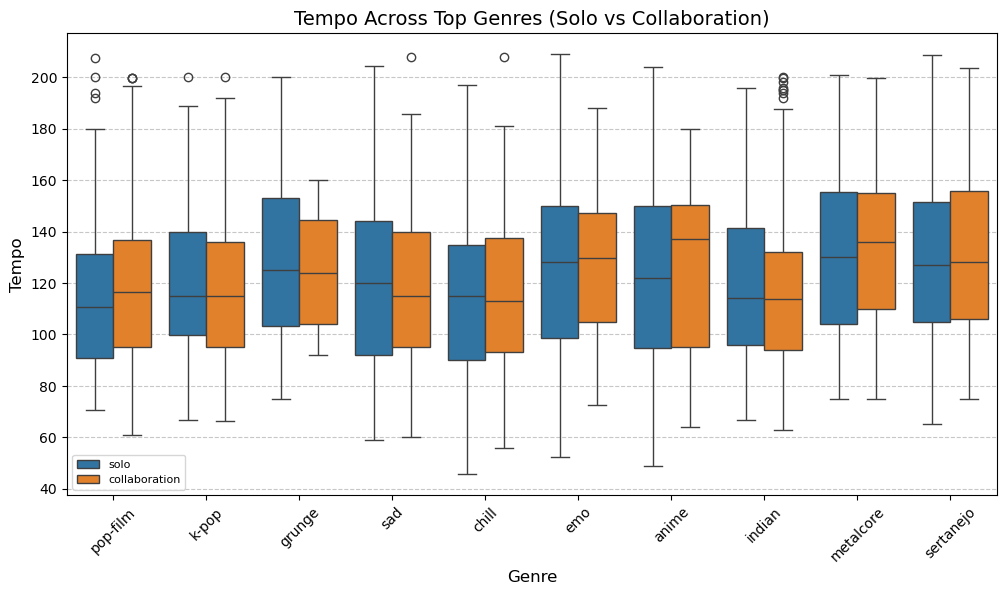

Genre: pop-film
T-statistic: -1.59260, P-value: 0.11160
No significant difference in tempo between solo and collaboration tracks for pop-film

Genre: k-pop
T-statistic: 1.36178, P-value: 0.17364
No significant difference in tempo between solo and collaboration tracks for k-pop

Genre: grunge
T-statistic: 1.17733, P-value: 0.24000
No significant difference in tempo between solo and collaboration tracks for grunge

Genre: sad
T-statistic: 1.07012, P-value: 0.28493
No significant difference in tempo between solo and collaboration tracks for sad

Genre: chill
T-statistic: -0.85442, P-value: 0.39321
No significant difference in tempo between solo and collaboration tracks for chill

Genre: emo
T-statistic: -0.22180, P-value: 0.82454
No significant difference in tempo between solo and collaboration tracks for emo

Genre: anime
T-statistic: -0.72176, P-value: 0.47091
No significant difference in tempo between solo and collaboration tracks for anime

Genre: indian
T-statistic: 1.54770, P-value:

In [36]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='all_genres', y='tempo', hue='collaboration', order=top_genres)
plt.title('Tempo Across Top Genres (Solo vs Collaboration)', fontsize=14)
plt.xlabel('Genre', fontsize=12)
plt.ylabel('Tempo', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.legend( fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

testing('tempo')

### 8. Valence

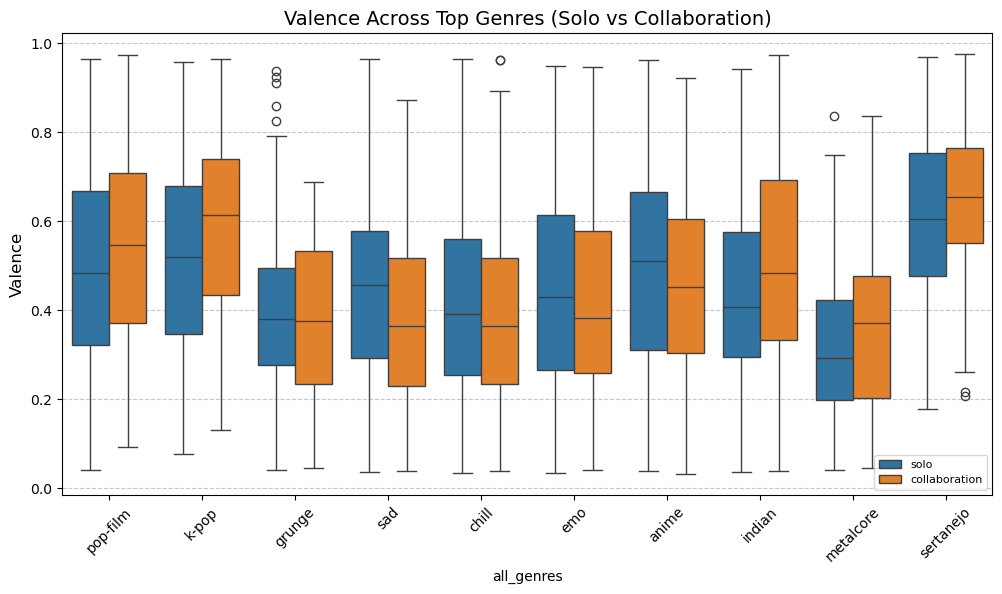

Genre: pop-film
T-statistic: -2.42928, P-value: 0.01532
Significant difference in valence between solo and collaboration tracks for pop-film
(Collaboration mean: 0.538, Solo mean: 0.502)
-> valence increase with collaboration. 

Genre: k-pop
T-statistic: -5.06577, P-value: 0.00000
Significant difference in valence between solo and collaboration tracks for k-pop
(Collaboration mean: 0.590, Solo mean: 0.518)
-> valence increase with collaboration. 

Genre: grunge
T-statistic: 0.43713, P-value: 0.66233
No significant difference in valence between solo and collaboration tracks for grunge

Genre: sad
T-statistic: 3.80802, P-value: 0.00015
Significant difference in valence between solo and collaboration tracks for sad
(Collaboration mean: 0.392, Solo mean: 0.450)
-> valence decreases with collaboration. 

Genre: chill
T-statistic: 0.71577, P-value: 0.47441
No significant difference in valence between solo and collaboration tracks for chill

Genre: emo
T-statistic: 1.33255, P-value: 0.18312
N

In [38]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top, x='all_genres', y='valence', hue='collaboration',order=top_genres)
plt.title('Valence Across Top Genres (Solo vs Collaboration)', fontsize=14)
plt.ylabel('Valence', fontsize=12)
plt.xticks(rotation=45, fontsize=10)
plt.legend( fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

testing('valence')


Number of increases per attribute:
danceability        3
energy              2
speechiness         4
acousticness        3
instrumentalness    1
liveness            1
valence             4
tempo               0
dtype: int64

Number of decreases per attribute:
danceability        0
energy              2
speechiness         0
acousticness        1
instrumentalness    1
liveness            2
valence             1
tempo               0
dtype: int64

Number of no changes per attribute:
danceability         7
energy               6
speechiness          6
acousticness         6
instrumentalness     8
liveness             7
valence              5
tempo               10
dtype: int64


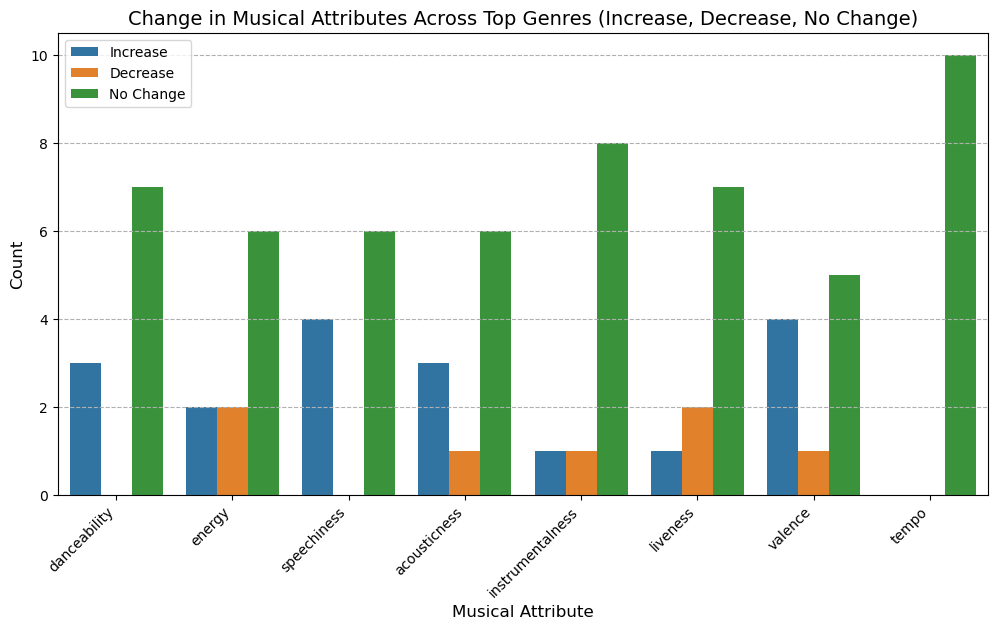


Rows where all attributes showed a change (either increase or decrease):
Empty DataFrame
Columns: [track_genre, danceability, energy, speechiness, acousticness, instrumentalness, liveness, valence, tempo]
Index: []

Rows where all attributes showed no change:
   index track_genre danceability energy speechiness acousticness  \
0      8   metalcore           no     no          no           no   

  instrumentalness liveness valence tempo  
0               no       no      no    no  


In [39]:

attributes = ['danceability', 'energy', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

# Define the top genres (replace this with your actual 'top_genres' list)
top_genres = ['pop-film', 'k-pop', 'grunge', 'sad', 'chill', 'emo', 'anime', 'indian', 'metalcore', 'sertanejo']

# Filter the dataset to include only the top 10 genres
df_top_genres = df_filtered[df_filtered['all_genres'].isin(top_genres)]

# Initialize an empty list to hold the results for each genre
results_list = []

# Loop through each top genre in the dataset
for genre in top_genres:
    genre_data = df_top_genres[df_top_genres['all_genres'] == genre]
    
    # Create a dictionary to hold the results for this genre
    genre_result = {'track_genre': genre}
    
    # Loop through each attribute to calculate t-test for solo and collaboration tracks
    for attribute in attributes:
        solo_data = genre_data[genre_data['collaboration'] == 'solo'][attribute]
        collab_data = genre_data[genre_data['collaboration'] == 'collaboration'][attribute]
        
        # Perform t-test
        t_stat, p_value = stats.ttest_ind(solo_data, collab_data)

        # If p-value is less than 0.05, significant difference is found
        if p_value < 0.05:
            mean_solo = solo_data.mean()
            mean_collab = collab_data.mean()

            # Determine the direction of change (increase or decrease)
            if mean_collab > mean_solo:
                genre_result[attribute] = 'increase'
            else:
                genre_result[attribute] = 'decrease'
        else:
            genre_result[attribute] = 'no'

    # Append the genre results to the list
    results_list.append(genre_result)

# Create a DataFrame from the results list
results_df = pd.DataFrame(results_list)

# Count the occurrences of 'increase', 'decrease', and 'no change'  
increase_count = (results_df.iloc[:, 1:] == 'increase').sum(axis=0)
decrease_count = (results_df.iloc[:, 1:] == 'decrease').sum(axis=0)
no_change_count = (results_df.iloc[:, 1:] == 'no').sum(axis=0)

print("Number of increases per attribute:")
print(increase_count)
print("\nNumber of decreases per attribute:")
print(decrease_count)
print("\nNumber of no changes per attribute:")
print(no_change_count)

change_counts_df = pd.DataFrame({
    'Attribute': increase_count.index,
    'Increase': increase_count.values,
    'Decrease': decrease_count.values,
    'No Change': no_change_count.values})

# Reshape the data
change_counts_df = change_counts_df.melt(id_vars='Attribute', value_vars=['Increase', 'Decrease', 'No Change'],
                                         var_name='Change Type',  value_name='Count')

# Ploting
plt.figure(figsize=(12, 6))
sns.barplot(data=change_counts_df, x='Attribute', y='Count', hue='Change Type')

plt.title('Change in Musical Attributes Across Top Genres (Increase, Decrease, No Change)', fontsize=14)
plt.xlabel('Musical Attribute', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.legend(fontsize=10)
plt.grid(axis='y', linestyle='--')

plt.show()

# Display rows showed either an increase or decrease
all_change_rows = results_df[results_df.iloc[:, 1:].apply(lambda x: all(x != 'no'), axis=1)]
print("\nRows where all attributes showed a change (either increase or decrease):")
print(all_change_rows)

# Display rows : no change
no_change_rows = results_df[results_df.iloc[:, 1:].apply(lambda x: all(x == 'no'), axis=1)]
print("\nRows where all attributes showed no change:")
print(no_change_rows.reset_index())



1. **Danceability and Energy**: Both danceability (3 increases) and energy (2 increases and 2 decreases) saw some positive changes when comparing collaboration to solo tracks. This suggests that collaboration may often lead to more energetic and danceable music, likely due to the dynamic interplay between different artists' styles and contributio. 

2. **Speechiness and Valence**: Speechiness (4 increases) and valence (4 increases) showed positive changes, indicating tct. Collaboration could enhance the diversity and richness ofical message, potentially leading to more expressive or emotional songs that resonate deeply with audiences.

3. **Acousticness and Instrumentalness**: These attributes showed fewer increases (acousticness: 3, instrumentalness: 1), and there were fewer decreases. This suggests that while collaboration can influence the overall vibe and complexity of the track, the use of acoustic or instrumental elements might not change drastically between solo and collaboration tr tions.

4. **Liveness and Tempo**: Liveness had 1 increase and 2 decreases, indicating a slight reduction in the presence of live performance elements in collaboration tracks, possibly due to more studio-focused production. Tempo showed no changes, suggesting that the speed of the track remains relatively stable in both solo and collaborative efforts, indicating a consistency in genre preferences for rhythmic pacing.

5. **No Changes**: A significant number of "no change" values across attributes like instrumentalness (8) and tempo (10) indicate that for many genres, the key musical elements remain constant regardless of whether the track is a solo effort or a collaboration. This stability in certain attributes suggests that these elements are foundational to the genre's identity and may not be easily altered by the presence of additional artists.

### Why is this useful?
This insight into the impact of collaboration versus solo work on musical attributes is valuable for artists and producers because it shows how collaboration can modify or enhance certain aspects of a track. For example, collaboration could be strategically used to enhance danceability, energy, and speechiness, which are attractive qualities for commercial music and live performances. On the other hand, aspects like tempo and acousticness might remain consistent, providing a sense of stability that aligns with the genre's traditional characteristics.

For artists, understanding these trends can help guide collaboration decisions, whether they want to enhance emotind speechiness) or boost energy and danceability for a more engaging, upbeat sound. Similarly, producers can use this knowledge to determine where to innovate and where to maintain consistency to cater to listener preferences and market trends.rger audiences.